# Лабораторна робота №3
## Моделювання кінотеатру за допомогою SimPy

**Мета:** Визначити оптимальну кількість працівників кінотеатру для підтримання середнього часу очікування менше 10 хвилин.

### Встановлення необхідних бібліотек

In [1]:
%pip install numpy pandas matplotlib seaborn simpy tabulate --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import simpy
import random
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Tuple
import logging
import sys

# Налаштування стилю графіків
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Налаштування логування
logger = logging.getLogger(__name__)
logger.setLevel(logging.INFO)
handler = logging.StreamHandler(sys.stdout)
logger.addHandler(handler)

## Частина 1: Моделювання кінотеатру

### Опис системи
Кінотеатр отримує погані відгуки через довгий час очікування. Необхідно знайти оптимальну кількість працівників для забезпечення середнього часу очікування не більше 10 хвилин.

### 1.1 Створення класу Theater

In [3]:
class Theater:
    """Клас для моделювання кінотеатру"""

    def __init__(self, env, num_cashiers, num_servers, num_ushers):
        self.env = env
        self.cashier = simpy.Resource(env, num_cashiers)
        self.server = simpy.Resource(env, num_servers)
        self.usher = simpy.Resource(env, num_ushers)

    def purchase_ticket(self, moviegoer):
        """Процес покупки квитка (1-3 хвилини)"""
        logger.debug(f"{moviegoer} починає купувати квиток у {self.env.now:.2f}")
        yield self.env.timeout(random.randint(1, 3))
        logger.debug(f"{moviegoer} закінчує купувати квиток у {self.env.now:.2f}")

    def check_ticket(self, moviegoer):
        """Процес перевірки квитка (3 секунди = 0.05 хвилини)"""
        logger.debug(f"{moviegoer} починає перевірку квитка у {self.env.now:.2f}")
        yield self.env.timeout(3 / 60)
        logger.debug(f"{moviegoer} закінчує перевірку квитка у {self.env.now:.2f}")

    def sell_food(self, moviegoer):
        """Процес продажу їжі (1-5 хвилин)"""
        logger.debug(f"{moviegoer} починає купувати їжу у {self.env.now:.2f}")
        yield self.env.timeout(random.randint(1, 5))
        logger.debug(f"{moviegoer} закінчує купувати їжу у {self.env.now:.2f}")

### 1.2 Функція переміщення глядача через кінотеатр

In [4]:
def go_to_movies(env, moviegoer, theater, wait_times):
    """Процес проходження глядача через кінотеатр"""
    arrival_time = env.now
    
    # Покупка квитка
    with theater.cashier.request() as request:
        yield request
        yield env.process(theater.purchase_ticket(moviegoer))
    
    # Перевірка квитка
    with theater.usher.request() as request:
        yield request
        yield env.process(theater.check_ticket(moviegoer))
    
    # Купівля їжі (50% ймовірність)
    if random.choice([True, False]):
        with theater.server.request() as request:
            yield request
            yield env.process(theater.sell_food(moviegoer))
    
    # Розрахунок часу очікування
    wait_time = env.now - arrival_time
    wait_times.append(wait_time)

### 1.3 Функція запуску симуляції

In [5]:
def run_theater(env, num_cashiers, num_servers, num_ushers, wait_times):
    """Запуск симуляції кінотеатру"""
    theater = Theater(env, num_cashiers, num_servers, num_ushers)
    
    # Початкові 3 глядачі
    for moviegoer in range(3):
        env.process(go_to_movies(env, moviegoer, theater, wait_times))
    
    # Генерація нових глядачів кожні 12 секунд (0.20 хвилини)
    moviegoer = 3
    while True:
        yield env.timeout(0.20)
        moviegoer += 1
        env.process(go_to_movies(env, moviegoer, theater, wait_times))

### 1.4 Допоміжні функції для розрахунку результатів

In [6]:
def calculate_wait_time(wait_times: List[float]) -> Tuple[int, int]:
    """Розрахунок середнього часу очікування"""
    if not wait_times:
        return 0, 0
    
    average_wait = statistics.mean(wait_times)
    minutes, frac_minutes = divmod(average_wait, 1)
    seconds = frac_minutes * 60
    return round(minutes), round(seconds)

def simulate_theater(num_cashiers, num_servers, num_ushers, 
                    runtime=90) -> Tuple[int, int, float]:
    """Запуск однієї симуляції кінотеатру"""
    wait_times = []
    
    env = simpy.Environment()
    env.process(run_theater(env, num_cashiers, num_servers, num_ushers, wait_times))
    env.run(until=runtime)
    
    mins, secs = calculate_wait_time(wait_times)
    avg_wait = statistics.mean(wait_times) if wait_times else 0
    
    return mins, secs, avg_wait

## Частина 2: Виконання загальних завдань

### Завдання 1: Визначити кількість персоналу для середнього часу < 10 хв

In [7]:
logger.info("=" * 70)
logger.info("ЗАВДАННЯ 1: Пошук оптимальної кількості персоналу (час < 10 хв)")
logger.info("=" * 70)

# Тестування різних комбінацій
results_task1 = []

# Починаємо з базових значень
for cashiers in range(1, 10):
    for servers in range(1, 10):
        for ushers in range(1, 10):
            mins, secs, avg_wait = simulate_theater(cashiers, servers, ushers)
            results_task1.append(
                {
                    "Касири": cashiers,
                    "Офіціанти": servers,
                    "Швейцари": ushers,
                    "Час (хв)": mins,
                    "Час (сек)": secs,
                    "Середній час (хв)": round(avg_wait, 2),
                }
            )

            logger.debug(
                f"Касири: {cashiers}, Офіціанти: {servers}, Швейцари: {ushers} "
                f"→ {mins} хв {secs} сек ({avg_wait:.2f} хв)"
            )

# Створюємо DataFrame
df_task1 = pd.DataFrame(results_task1)
df_task1_cols = df_task1.columns.tolist()
df_task1["Кількість персоналу"] = (
    df_task1["Касири"] + df_task1["Офіціанти"] + df_task1["Швейцари"]
)
df_task1_filtered = (
    df_task1[df_task1["Середній час (хв)"] < 10]
    .sort_values("Кількість персоналу")
    .head(10)[df_task1_cols]
)

logger.info("\n📊 Топ-10 достатніх рішень для завдання 1:")
logger.info(df_task1_filtered.to_markdown(index=False))

ЗАВДАННЯ 1: Пошук оптимальної кількості персоналу (час < 10 хв)

📊 Топ-10 достатніх рішень для завдання 1:
|   Касири |   Офіціанти |   Швейцари |   Час (хв) |   Час (сек) |   Середній час (хв) |
|---------:|------------:|-----------:|-----------:|------------:|--------------------:|
|        9 |           7 |          1 |          8 |           4 |                8.07 |
|        9 |           7 |          2 |          9 |          17 |                9.28 |
|        9 |           8 |          1 |          8 |          30 |                8.5  |
|        9 |           4 |          6 |          9 |          25 |                9.41 |
|        9 |           7 |          3 |          9 |          55 |                9.91 |
|        9 |           6 |          4 |          7 |          53 |                7.89 |
|        9 |           8 |          2 |          8 |          27 |                8.44 |
|        9 |           9 |          1 |          9 |          13 |                9.22 |
|  

### Завдання 2: При 10 касирах знайти персонал для часу < 9 хв

In [8]:
logger.info("=" * 70)
logger.info("ЗАВДАННЯ 2: При 10 касирах, час < 9 хв")
logger.info("=" * 70)

results_task2 = []
num_cashiers_fixed = 10

for servers in range(1, 7):
    for ushers in range(1, 7):
        mins, secs, avg_wait = simulate_theater(num_cashiers_fixed, servers, ushers)
        results_task2.append(
            {
                "Касири": num_cashiers_fixed,
                "Офіціанти": servers,
                "Швейцари": ushers,
                "Час (хв)": mins,
                "Час (сек)": secs,
                "Середній час (хв)": round(avg_wait, 2),
            }
        )

        logger.debug(
            f"Офіціанти: {servers}, Швейцари: {ushers} "
            f"→ {mins} хв {secs} сек ({avg_wait:.2f} хв)"
        )

df_task2 = pd.DataFrame(results_task2)
df_task2_cols = df_task2.columns.tolist()
df_task2["Кількість персоналу"] = (
    df_task2["Касири"] + df_task2["Офіціанти"] + df_task2["Швейцари"]
)
df_task2_filtered = (
    df_task2[df_task2["Середній час (хв)"] < 9]
    .sort_values("Кількість персоналу")
    .head(10)[df_task2_cols]
)

logger.info("\n📊 Топ-10 достатніх рішень для завдання 2:")
logger.info(df_task2_filtered.to_markdown(index=False))

ЗАВДАННЯ 2: При 10 касирах, час < 9 хв

📊 Топ-10 достатніх рішень для завдання 2:
|   Касири |   Офіціанти |   Швейцари |   Час (хв) |   Час (сек) |   Середній час (хв) |
|---------:|------------:|-----------:|-----------:|------------:|--------------------:|
|       10 |           1 |          1 |          6 |          26 |                6.44 |
|       10 |           1 |          2 |          7 |          23 |                7.38 |
|       10 |           1 |          3 |          7 |           5 |                7.08 |
|       10 |           1 |          4 |          7 |           0 |                7.01 |
|       10 |           1 |          5 |          7 |          11 |                7.19 |
|       10 |           4 |          2 |          8 |          46 |                8.76 |
|       10 |           5 |          1 |          8 |          35 |                8.59 |
|       10 |           1 |          6 |          7 |          50 |                7.83 |
|       10 |           5 |  

### Завдання 3: Знайти персонал для часу < 5 хв

In [9]:
logger.info("=" * 70)
logger.info("ЗАВДАННЯ 3: Пошук персоналу для часу < 5 хв")
logger.info("=" * 70)

results_task3 = []

for cashiers in range(1, 15):
    for servers in range(1, 15):
        for ushers in range(1, 15):
            mins, secs, avg_wait = simulate_theater(cashiers, servers, ushers)
            results_task3.append(
                {
                    "Касири": cashiers,
                    "Офіціанти": servers,
                    "Швейцари": ushers,
                    "Час (хв)": mins,
                    "Час (сек)": secs,
                    "Середній час (хв)": round(avg_wait, 2),
                }
            )

            logger.debug(
                f"Касири: {cashiers}, Офіціанти: {servers}, Швейцари: {ushers} "
                f"→ {mins} хв {secs} сек ({avg_wait:.2f} хв)"
            )

df_task3 = pd.DataFrame(results_task3)
df_task3_cols = df_task3.columns.tolist()
df_task3["Кількість персоналу"] = (
    df_task3["Касири"] + df_task3["Офіціанти"] + df_task3["Швейцари"]
)
df_task3_filtered = (
    df_task3[df_task3["Середній час (хв)"] < 5]
    .sort_values("Кількість персоналу")
    .head(10)[df_task3_cols]
)

logger.info("\n📊 Топ-10 достатніх рішень для завдання 3:")
logger.info(df_task3_filtered.to_markdown(index=False))

ЗАВДАННЯ 3: Пошук персоналу для часу < 5 хв

📊 Топ-10 достатніх рішень для завдання 3:
|   Касири |   Офіціанти |   Швейцари |   Час (хв) |   Час (сек) |   Середній час (хв) |
|---------:|------------:|-----------:|-----------:|------------:|--------------------:|
|       10 |           8 |          1 |          4 |          33 |                4.55 |
|       10 |           7 |          3 |          4 |          26 |                4.43 |
|       11 |           8 |          1 |          4 |           1 |                4.01 |
|       11 |           7 |          2 |          4 |          53 |                4.88 |
|       10 |           9 |          1 |          3 |          51 |                3.85 |
|       11 |           9 |          1 |          3 |          48 |                3.8  |
|       10 |           8 |          3 |          4 |          10 |                4.17 |
|       11 |           7 |          3 |          4 |          24 |                4.39 |
|       12 |           

### Завдання 4: 7 касирів, 10 швейцарів, 8 офіціантів - який час?

In [10]:
logger.info("=" * 70)
logger.info("ЗАВДАННЯ 4: 7 касирів, 10 швейцарів, 8 офіціантів")
logger.info("=" * 70)

mins, secs, avg_wait = simulate_theater(7, 8, 10)

result_task4 = {
    'Касири': 7,
    'Офіціанти': 8,
    'Швейцари': 10,
    'Час (хв)': mins,
    'Час (сек)': secs,
    'Середній час (хв)': round(avg_wait, 2)
}

logger.info(f"\n✅ Результат: {mins} хв {secs} сек ({avg_wait:.2f} хв)")
df_task4 = pd.DataFrame([result_task4])
logger.info("\n" + df_task4.to_markdown(index=False))

ЗАВДАННЯ 4: 7 касирів, 10 швейцарів, 8 офіціантів

✅ Результат: 18 хв 55 сек (18.92 хв)

|   Касири |   Офіціанти |   Швейцари |   Час (хв) |   Час (сек) |   Середній час (хв) |
|---------:|------------:|-----------:|-----------:|------------:|--------------------:|
|        7 |           8 |         10 |         18 |          55 |               18.92 |


### Візуалізація результатів кінотеатру

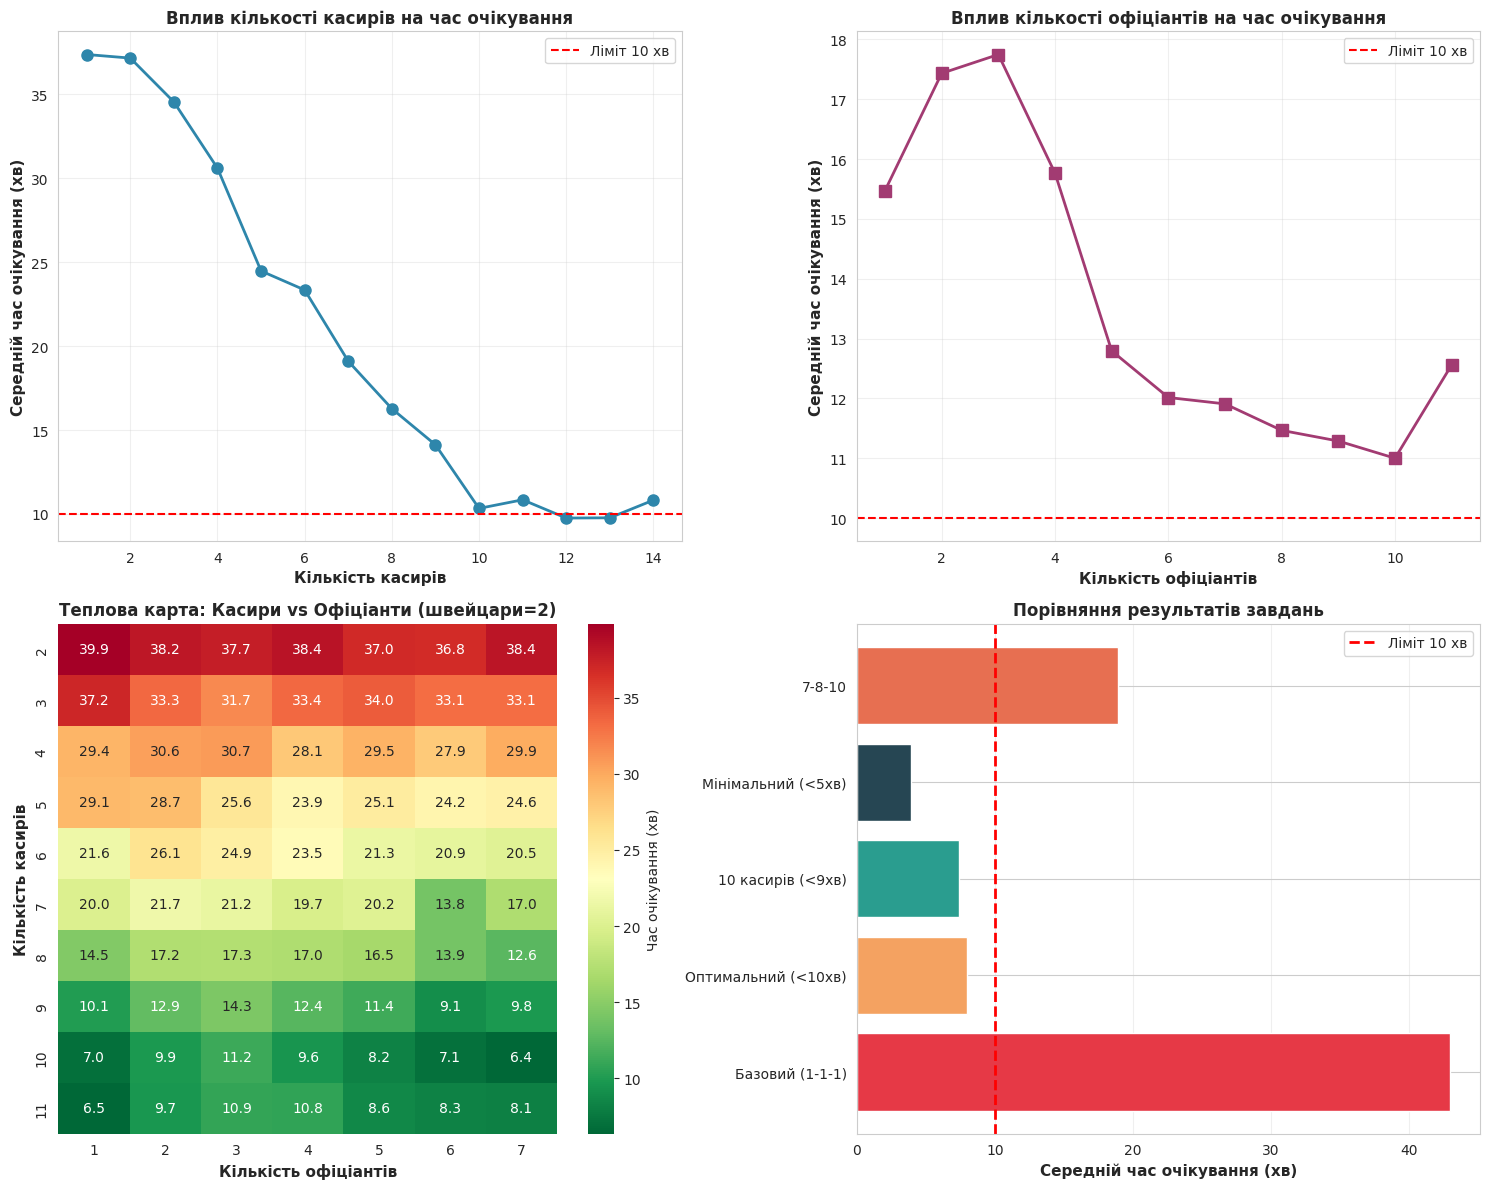

In [11]:
# Графік 1: Вплив кількості касирів на час очікування
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Вплив касирів (при фіксованих офіціантах=3, швейцарах=2)
cashier_impact = []
for cashiers in range(1, 15):
    _, _, avg_wait = simulate_theater(cashiers, 3, 2)
    cashier_impact.append({'Касири': cashiers, 'Час очікування (хв)': avg_wait})

df_cashier = pd.DataFrame(cashier_impact)
axes[0, 0].plot(df_cashier['Касири'], df_cashier['Час очікування (хв)'], 
                marker='o', linewidth=2, markersize=8, color='#2E86AB')
axes[0, 0].axhline(y=10, color='red', linestyle='--', label='Ліміт 10 хв')
axes[0, 0].set_xlabel('Кількість касирів', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Середній час очікування (хв)', fontsize=11, fontweight='bold')
axes[0, 0].set_title('Вплив кількості касирів на час очікування', fontsize=12, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Вплив офіціантів (при фіксованих касирах=8, швейцарах=2)
server_impact = []
for servers in range(1, 12):
    _, _, avg_wait = simulate_theater(8, servers, 2)
    server_impact.append({'Офіціанти': servers, 'Час очікування (хв)': avg_wait})

df_server = pd.DataFrame(server_impact)
axes[0, 1].plot(df_server['Офіціанти'], df_server['Час очікування (хв)'], 
                marker='s', linewidth=2, markersize=8, color='#A23B72')
axes[0, 1].axhline(y=10, color='red', linestyle='--', label='Ліміт 10 хв')
axes[0, 1].set_xlabel('Кількість офіціантів', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Середній час очікування (хв)', fontsize=11, fontweight='bold')
axes[0, 1].set_title('Вплив кількості офіціантів на час очікування', fontsize=12, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Теплова карта: Касири vs Офіціанти
heatmap_data = []
cashiers_range = range(2, 12)
servers_range = range(1, 8)

for cashiers in cashiers_range:
    row = []
    for servers in servers_range:
        _, _, avg_wait = simulate_theater(cashiers, servers, 2)
        row.append(avg_wait)
    heatmap_data.append(row)

heatmap_df = pd.DataFrame(heatmap_data, 
                          index=[f'{c}' for c in cashiers_range],
                          columns=[f'{s}' for s in servers_range])

sns.heatmap(heatmap_df, annot=True, fmt='.1f', cmap='RdYlGn_r', 
            ax=axes[1, 0], cbar_kws={'label': 'Час очікування (хв)'})
axes[1, 0].set_xlabel('Кількість офіціантів', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('Кількість касирів', fontsize=11, fontweight='bold')
axes[1, 0].set_title('Теплова карта: Касири vs Офіціанти (швейцари=2)', 
                     fontsize=12, fontweight='bold')

# 4. Порівняння всіх завдань
tasks_comparison = pd.DataFrame([
    {'Завдання': 'Базовий (1-1-1)', 'Час (хв)': simulate_theater(1, 1, 1)[2]},
    {'Завдання': 'Оптимальний (<10хв)', 'Час (хв)': df_task1_filtered.iloc[-1]['Середній час (хв)']},
    {'Завдання': '10 касирів (<9хв)', 'Час (хв)': df_task2_filtered.iloc[-1]['Середній час (хв)']},
    {'Завдання': 'Мінімальний (<5хв)', 'Час (хв)': df_task3_filtered.iloc[-1]['Середній час (хв)']},
    {'Завдання': '7-8-10', 'Час (хв)': result_task4['Середній час (хв)']}
])

colors = ['#E63946', '#F4A261', '#2A9D8F', '#264653', '#E76F51']
axes[1, 1].barh(tasks_comparison['Завдання'], tasks_comparison['Час (хв)'], color=colors)
axes[1, 1].axvline(x=10, color='red', linestyle='--', linewidth=2, label='Ліміт 10 хв')
axes[1, 1].set_xlabel('Середній час очікування (хв)', fontsize=11, fontweight='bold')
axes[1, 1].set_title('Порівняння результатів завдань', fontsize=12, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

## Частина 3: Індивідуальне завдання - Банківське відділення

### Опис системи

**Багатоканальна СМО з відмовами** для банківського відділення:

- **Тип системи**: M/M/c/c (черга Маркова з обмеженою кількістю місць)
- **Вхідний потік**: Клієнти прибувають з інтенсивністю R (експоненціальний розподіл)
- **Час обслуговування**: Експоненціальний розподіл з параметром T
- **Кількість каналів (операторів)**: c
- **Місткість системи**: c (немає черги, якщо всі оператори зайняті - відмова)

**Параметри моделі:**
- Середня інтенсивність прибуття: 20-50 клієнтів/годину
- Середній час обслуговування: 5-15 хвилин
- Кількість операторів: 2-8
- Час роботи: 8 годин (480 хвилин)

### 3.1 Клас BankBranch

In [12]:
# Revised BankBranch (add current_busy) and robust client_arrival
class BankBranch:
    def __init__(self, env, num_tellers, service_time_mean, rng_service):
        self.env = env
        self.tellers = simpy.Resource(env, num_tellers)
        self.service_time_mean = service_time_mean
        self.rng_service = rng_service

        # Stats
        self.clients_arrived = 0
        self.clients_served = 0
        self.clients_rejected = 0
        self.wait_times = []
        self.service_times = []

        # Manual busy counter (reliable)
        self.current_busy = 0


    def serve_client(self, client_id):
        """Service time ~ Exponential(mean = service_time_mean)."""
        logger.debug(f"Клієнт {client_id} починає обслуговування у {self.env.now:.2f}")
        service_time = float(self.rng_service.exponential(self.service_time_mean))
        yield self.env.timeout(service_time)
        self.service_times.append(service_time)
        logger.debug(f"Клієнт {client_id} закінчує обслуговування у {self.env.now:.2f}")


def client_arrival(env, bank, arrival_rate_per_hour, rng_arrival):
    """
    Generates arrivals as an independent Poisson process.
    Each accepted client spawns a separate service process.
    """
    client_id = 0
    mean_interarrival = 60.0 / arrival_rate_per_hour  # minutes

    while True:
        interarrival = float(rng_arrival.exponential(mean_interarrival))
        yield env.timeout(interarrival)

        client_id += 1
        bank.clients_arrived += 1
        arrival_time = env.now

        req = bank.tellers.request()
        res = yield req | env.timeout(0)

        if req not in res:
            try:
                req.cancel()
            except Exception:
                pass
            bank.clients_rejected += 1
            continue

        bank.current_busy += 1
        wait_time = env.now - arrival_time
        bank.wait_times.append(wait_time)
        bank.clients_served += 1

        # non-blocking: start service as a parallel process
        env.process(handle_service(env, bank, client_id, req))


def handle_service(env, bank, client_id, req):
    """Separate coroutine for service handling."""
    try:
        yield env.process(bank.serve_client(client_id))
    finally:
        bank.tellers.release(req)
        bank.current_busy -= 1

### 3.2 Функція симуляції банку

In [13]:
def simulate_bank(num_tellers, arrival_rate, service_time_mean, simulation_time=480, seed=None):
    """
    Run simulation using NumPy RNGs (arrival & service separate).
    - num_tellers: int
    - arrival_rate: clients / hour
    - service_time_mean: minutes
    - simulation_time: minutes
    - seed: int or None (for reproducibility)
    """
    rng_arrival = np.random.default_rng(seed if seed is not None else None)
    rng_service = np.random.default_rng((seed + 1) if seed is not None else None)

    env = simpy.Environment()
    bank = BankBranch(env, num_tellers, service_time_mean, rng_service)
    env.process(client_arrival(env, bank, arrival_rate, rng_arrival))
    env.run(until=simulation_time)

    arrived = bank.clients_arrived
    served = bank.clients_served
    rejected = bank.clients_rejected
    rejection_rate = (rejected / arrived * 100) if arrived > 0 else 0.0
    avg_service_time = statistics.mean(bank.service_times) if bank.service_times else 0.0
    total_busy = sum(bank.service_times)
    utilization = (total_busy / (num_tellers * simulation_time) * 100) if (num_tellers * simulation_time) > 0 else 0.0

    return {
        'Оператори': num_tellers,
        'Прибуло клієнтів': arrived,
        'Обслужено': served,
        'Відмовлено': rejected,
        'Ймовірність відмови (%)': round(rejection_rate, 4),
        'Середній час обслуговування (хв)': round(avg_service_time, 6),
        'Завантаженість (%)': round(utilization, 4)
    }

### 3.3 Дослідження параметрів банківської системи

In [14]:
logger.info("=" * 80)
logger.info("ІНДИВІДУАЛЬНЕ ЗАВДАННЯ: БАНКІВСЬКЕ ВІДДІЛЕННЯ")
logger.info("=" * 80)

# Базові параметри
base_arrival_rate = 50     # клієнтів/годину
base_service_time = 5       # хвилин
simulation_time = 480       # хвилин роботи

results_bank = []

logger.info(
    f"\n📊 Дослідження 1: Вплив кількості операторів (R={base_arrival_rate} кл/год, T={base_service_time} хв)"
)
logger.info("-" * 80)

for num_tellers in range(2, 9):
    result = simulate_bank(
        num_tellers, base_arrival_rate, base_service_time, simulation_time
    )
    results_bank.append(result)
    logger.debug(
        f"Оператори: {num_tellers} | Відмов: {result['Відмовлено']} "
        f"({result['Ймовірність відмови (%)']:.2f}%) | "
        f"Завантаженість: {result['Завантаженість (%)']:.1f}%"
    )

df_bank_tellers = pd.DataFrame(results_bank)
logger.info("\n" + df_bank_tellers.to_markdown(index=False))

ІНДИВІДУАЛЬНЕ ЗАВДАННЯ: БАНКІВСЬКЕ ВІДДІЛЕННЯ

📊 Дослідження 1: Вплив кількості операторів (R=50 кл/год, T=5 хв)
--------------------------------------------------------------------------------

|   Оператори |   Прибуло клієнтів |   Обслужено |   Відмовлено |   Ймовірність відмови (%) |   Середній час обслуговування (хв) |   Завантаженість (%) |
|------------:|-------------------:|------------:|-------------:|--------------------------:|-----------------------------------:|---------------------:|
|           2 |                403 |         133 |          270 |                   66.9975 |                            5.87337 |              81.3706 |
|           3 |                380 |         201 |          179 |                   47.1053 |                            5.07331 |              70.1103 |
|           4 |                400 |         286 |          114 |                   28.5    |                            4.5529  |              67.345  |
|           5 |                381 

### 3.4 Дослідження впливу інтенсивності прибуття

In [15]:
logger.info("📊 Дослідження 2: Вплив інтенсивності прибуття (оператори=5, T=10 хв)")
logger.info("-" * 80)

results_arrival = []
num_tellers_fixed = 5

for arrival_rate in [15, 20, 25, 30, 35, 40, 45, 50]:
    result = simulate_bank(num_tellers_fixed, arrival_rate, base_service_time, simulation_time)
    result['Інтенсивність прибуття (кл/год)'] = arrival_rate
    results_arrival.append(result)
    logger.debug(f"R={arrival_rate} кл/год | Відмов: {result['Відмовлено']} "
          f"({result['Ймовірність відмови (%)']:.2f}%) | "
          f"Обслужено: {result['Обслужено']}")

df_bank_arrival = pd.DataFrame(results_arrival)
logger.info("\n" + df_bank_arrival[['Інтенсивність прибуття (кл/год)', 'Прибуло клієнтів', 
                               'Обслужено', 'Відмовлено', 'Ймовірність відмови (%)']].to_markdown(index=False))

📊 Дослідження 2: Вплив інтенсивності прибуття (оператори=5, T=10 хв)
--------------------------------------------------------------------------------

|   Інтенсивність прибуття (кл/год) |   Прибуло клієнтів |   Обслужено |   Відмовлено |   Ймовірність відмови (%) |
|----------------------------------:|-------------------:|------------:|-------------:|--------------------------:|
|                                15 |                121 |         121 |            0 |                    0      |
|                                20 |                149 |         148 |            1 |                    0.6711 |
|                                25 |                210 |         198 |           12 |                    5.7143 |
|                                30 |                242 |         214 |           28 |                   11.5702 |
|                                35 |                251 |         244 |            7 |                    2.7888 |
|                                40 |

### 3.5 Дослідження впливу часу обслуговування

In [16]:
logger.info("📊 Дослідження 3: Вплив часу обслуговування (оператори=5, R=30 кл/год)")
logger.info("-" * 80)

results_service = []

for service_time in [5, 7, 10, 12, 15]:
    result = simulate_bank(num_tellers_fixed, base_arrival_rate, service_time, simulation_time)
    result['Час обслуговування (хв)'] = service_time
    results_service.append(result)
    logger.debug(f"T={service_time} хв | Відмов: {result['Відмовлено']} "
          f"({result['Ймовірність відмови (%)']:.2f}%) | "
          f"Завантаженість: {result['Завантаженість (%)']:.1f}%")

df_bank_service = pd.DataFrame(results_service)
logger.info("\n" + df_bank_service[['Час обслуговування (хв)', 'Обслужено', 'Відмовлено', 
                               'Ймовірність відмови (%)', 'Завантаженість (%)']].to_markdown(index=False))

📊 Дослідження 3: Вплив часу обслуговування (оператори=5, R=30 кл/год)
--------------------------------------------------------------------------------

|   Час обслуговування (хв) |   Обслужено |   Відмовлено |   Ймовірність відмови (%) |   Завантаженість (%) |
|--------------------------:|------------:|-------------:|--------------------------:|---------------------:|
|                         5 |         313 |           88 |                   21.9451 |              61.0671 |
|                         7 |         265 |          164 |                   38.2284 |              77.9038 |
|                        10 |         193 |          176 |                   47.6965 |              81.3632 |
|                        12 |         192 |          198 |                   50.7692 |              82.9809 |
|                        15 |         166 |          253 |                   60.3819 |              86.7358 |


### 3.6 Зворотна задача: знайти оптимальну кількість операторів

In [17]:
logger.info("📊 Дослідження 4: Зворотна задача - мінімізація відмов")
logger.info("-" * 80)
logger.info("Мета: Знайти мінімальну кількість операторів для ймовірності відмови < 5%")
logger.info("-" * 80)

results_optimization = []

for arrival_rate in [25, 30, 35, 40]:
    for num_tellers in range(2, 12):
        result = simulate_bank(num_tellers, arrival_rate, base_service_time, simulation_time)
        result['Інтенсивність прибуття (кл/год)'] = arrival_rate
        
        if result['Ймовірність відмови (%)'] < 5:
            results_optimization.append(result)
            logger.debug(f"R={arrival_rate} кл/год → Потрібно {num_tellers} операторів "
                  f"(відмова: {result['Ймовірність відмови (%)']:.2f}%)")
            break

df_optimization = pd.DataFrame(results_optimization)
logger.info("\n📋 Оптимальні конфігурації:")
logger.info(df_optimization[['Інтенсивність прибуття (кл/год)', 'Оператори', 
                       'Ймовірність відмови (%)', 'Завантаженість (%)']].to_markdown(index=False))

📊 Дослідження 4: Зворотна задача - мінімізація відмов
--------------------------------------------------------------------------------
Мета: Знайти мінімальну кількість операторів для ймовірності відмови < 5%
--------------------------------------------------------------------------------

📋 Оптимальні конфігурації:
|   Інтенсивність прибуття (кл/год) |   Оператори |   Ймовірність відмови (%) |   Завантаженість (%) |
|----------------------------------:|------------:|--------------------------:|---------------------:|
|                                25 |           6 |                    0.9615 |              34.0356 |
|                                30 |           6 |                    1.7467 |              35.4585 |
|                                35 |           6 |                    3.7671 |              47.4343 |
|                                40 |           6 |                    4.6921 |              52.9447 |


### 3.7 Візуалізація результатів банківської системи

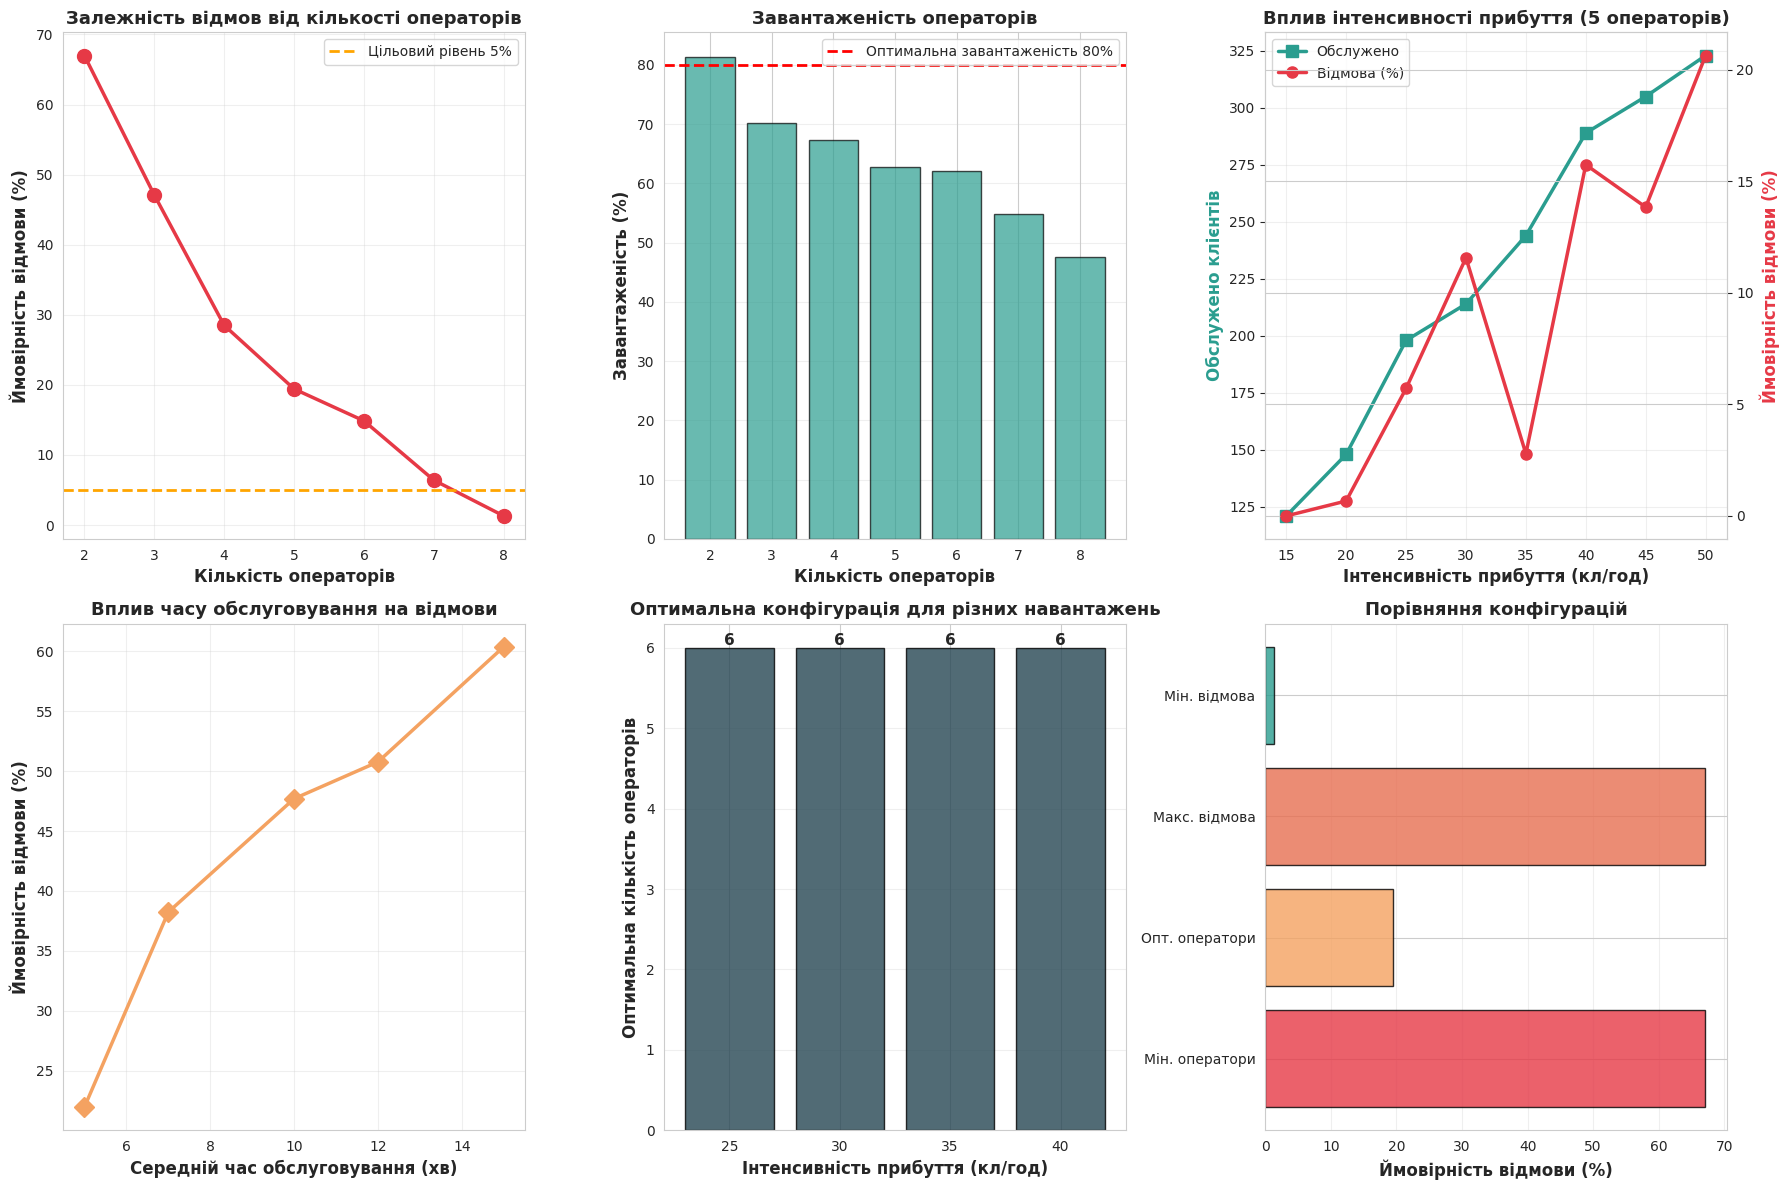

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Вплив кількості операторів на ймовірність відмови
axes[0, 0].plot(df_bank_tellers['Оператори'], df_bank_tellers['Ймовірність відмови (%)'],
                marker='o', linewidth=2.5, markersize=10, color='#E63946')
axes[0, 0].axhline(y=5, color='orange', linestyle='--', linewidth=2, label='Цільовий рівень 5%')
axes[0, 0].set_xlabel('Кількість операторів', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Ймовірність відмови (%)', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Залежність відмов від кількості операторів', fontsize=13, fontweight='bold')
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(True, alpha=0.3)

# 2. Завантаженість операторів
axes[0, 1].bar(df_bank_tellers['Оператори'], df_bank_tellers['Завантаженість (%)'],
               color='#2A9D8F', alpha=0.7, edgecolor='black')
axes[0, 1].axhline(y=80, color='red', linestyle='--', linewidth=2, label='Оптимальна завантаженість 80%')
axes[0, 1].set_xlabel('Кількість операторів', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Завантаженість (%)', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Завантаженість операторів', fontsize=13, fontweight='bold')
axes[0, 1].legend(fontsize=10)
axes[0, 1].grid(True, alpha=0.3, axis='y')

# 3. Вплив інтенсивності прибуття
ax3_1 = axes[0, 2]
ax3_2 = ax3_1.twinx()

line1 = ax3_1.plot(df_bank_arrival['Інтенсивність прибуття (кл/год)'], 
                    df_bank_arrival['Обслужено'],
                    marker='s', linewidth=2.5, markersize=8, color='#2A9D8F', label='Обслужено')
line2 = ax3_2.plot(df_bank_arrival['Інтенсивність прибуття (кл/год)'], 
                    df_bank_arrival['Ймовірність відмови (%)'],
                    marker='o', linewidth=2.5, markersize=8, color='#E63946', label='Відмова (%)')

ax3_1.set_xlabel('Інтенсивність прибуття (кл/год)', fontsize=12, fontweight='bold')
ax3_1.set_ylabel('Обслужено клієнтів', fontsize=12, fontweight='bold', color='#2A9D8F')
ax3_2.set_ylabel('Ймовірність відмови (%)', fontsize=12, fontweight='bold', color='#E63946')
ax3_1.set_title('Вплив інтенсивності прибуття (5 операторів)', fontsize=13, fontweight='bold')

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax3_1.legend(lines, labels, loc='upper left', fontsize=10)
ax3_1.grid(True, alpha=0.3)

# 4. Вплив часу обслуговування
axes[1, 0].plot(df_bank_service['Час обслуговування (хв)'], 
                df_bank_service['Ймовірність відмови (%)'],
                marker='D', linewidth=2.5, markersize=10, color='#F4A261')
axes[1, 0].set_xlabel('Середній час обслуговування (хв)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Ймовірність відмови (%)', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Вплив часу обслуговування на відмови', fontsize=13, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# 5. Оптимальні конфігурації
x_pos = range(len(df_optimization))
bars = axes[1, 1].bar(x_pos, df_optimization['Оператори'], 
                      color='#264653', alpha=0.8, edgecolor='black')
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(df_optimization['Інтенсивність прибуття (кл/год)'])
axes[1, 1].set_xlabel('Інтенсивність прибуття (кл/год)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Оптимальна кількість операторів', fontsize=12, fontweight='bold')
axes[1, 1].set_title('Оптимальна конфігурація для різних навантажень', fontsize=13, fontweight='bold')

# Додаємо значення на стовпчики
for i, bar in enumerate(bars):
    height = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2., height,
                    f'{int(height)}',
                    ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3, axis='y')

# 6. Порівняльна таблиця показників
comparison_data = pd.DataFrame({
    'Показник': ['Мін. оператори', 'Опт. оператори', 'Макс. відмова', 'Мін. відмова'],
    'Оператори': [2, 5, 2, 8],
    'Відмова (%)': [
        df_bank_tellers[df_bank_tellers['Оператори']==2]['Ймовірність відмови (%)'].values[0],
        df_bank_tellers[df_bank_tellers['Оператори']==5]['Ймовірність відмови (%)'].values[0],
        df_bank_tellers[df_bank_tellers['Оператори']==2]['Ймовірність відмови (%)'].values[0],
        df_bank_tellers[df_bank_tellers['Оператори']==8]['Ймовірність відмови (%)'].values[0]
    ]
})

colors_comparison = ['#E63946', '#F4A261', '#E76F51', '#2A9D8F']
axes[1, 2].barh(comparison_data['Показник'], comparison_data['Відмова (%)'], 
                color=colors_comparison, alpha=0.8, edgecolor='black')
axes[1, 2].set_xlabel('Ймовірність відмови (%)', fontsize=12, fontweight='bold')
axes[1, 2].set_title('Порівняння конфігурацій', fontsize=13, fontweight='bold')
axes[1, 2].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()